Fundação Getulio Vargas

Escola de Relações Internacionais

Ciência de Dados em Ambientes de Negócios, 2026.2

Professora Walkiria Resende

Alunas: Allegra Scheffer (C379009), Maria Isadora Camargo (C368703) e Maria Luisa (C378975)


Importando bibliotecas

In [ ]:
!pip install ucimlrepo

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import io
import urllib.request

Imprtando a base "Bank Marketing" da UCI

In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank-additional.zip"

resposta = urllib.request.urlopen(url)
arquivo_zip = zipfile.ZipFile(io.BytesIO(resposta.read()))

with arquivo_zip.open("bank-additional/bank-additional-full.csv") as arquivo:
    df = pd.read_csv(arquivo, sep=";")

print("Dimensões da base:", df.shape)
display(df.head())

Dimensões da base: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:
#A base de dados indica NANs como "unknown". Dessa forma, substituímos "unknown" por NaN em todo o dataset:
df = df.replace("unknown", np.nan)

# Perfilamento das colunas
perfil = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "nulos_%": (df.isna().mean() * 100).round(2),
    "n_unicos": df.nunique()
})

display(perfil)

# Verificação de duplicatas
print("Linhas duplicadas:", df.duplicated().sum())

# Distribuição da variável-alvo
print("\nDistribuição do alvo:")
print(df["y"].value_counts())

print("\nDistribuição percentual do alvo:")
print((df["y"].value_counts(normalize=True) * 100).round(2))

,tipo,nulos,nulos_%,n_unicos
age,int64,0,0.00,78
job,object,330,0.80,11
marital,object,80,0.19,3
education,object,1731,4.20,7
default,object,8597,20.87,2
housing,object,990,2.40,2
loan,object,990,2.40,2
contact,object,0,0.00,2
month,object,0,0.00,10
day_of_week,object,0,0.00,5


Linhas duplicadas: 12

Distribuição do alvo:
y
no     36548
yes     4640
Name: count, dtype: int64

Distribuição percentual do alvo:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64


In [ ]:
#Existem 12 linhas duplicadas, para ver quais são:
duplicadas = df[df.duplicated(keep=False)]

display(duplicadas)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1265,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
12260,36,retired,married,NaN,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,NaN,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16819,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16956,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no


Taxa geral de adesão: 11.27%


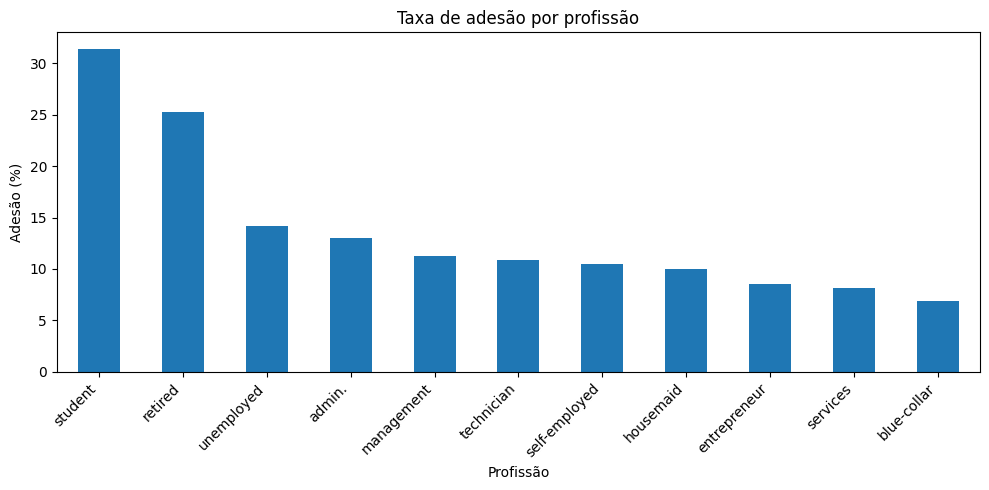

In [ ]:
# Taxa geral de adesão
taxa_adesao = (df["y"] == "yes").mean() * 100
print(f"Taxa geral de adesão: {taxa_adesao:.2f}%")

# Taxa de adesão por profissão
adesao_profissao = (
    df.assign(aderiu=df["y"].eq("yes"))
    .groupby("job")["aderiu"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

adesao_profissao.plot(kind="bar", figsize=(10, 5))
plt.title("Taxa de adesão por profissão")
plt.ylabel("Adesão (%)")
plt.xlabel("Profissão")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
#Para identificar se existem valores não compatíveis com a categoria:
numericas = df.select_dtypes(include="number")

display(numericas.describe().T)

# Idades iguais ou inferiores a zero
print("Idades inválidas:",
      (df["age"] <= 0).sum())

# Número de contatos na campanha atual
print("Campaign abaixo de 1:",
      (df["campaign"] < 1).sum())

# Valores negativos em variáveis que representam contagens
for coluna in ["age", "campaign", "previous"]:
    print(
        coluna,
        "negativos:",
        (df[coluna] < 0).sum()
    )

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


Idades inválidas: 0
Campaign abaixo de 1: 0
age negativos: 0
campaign negativos: 0
previous negativos: 0


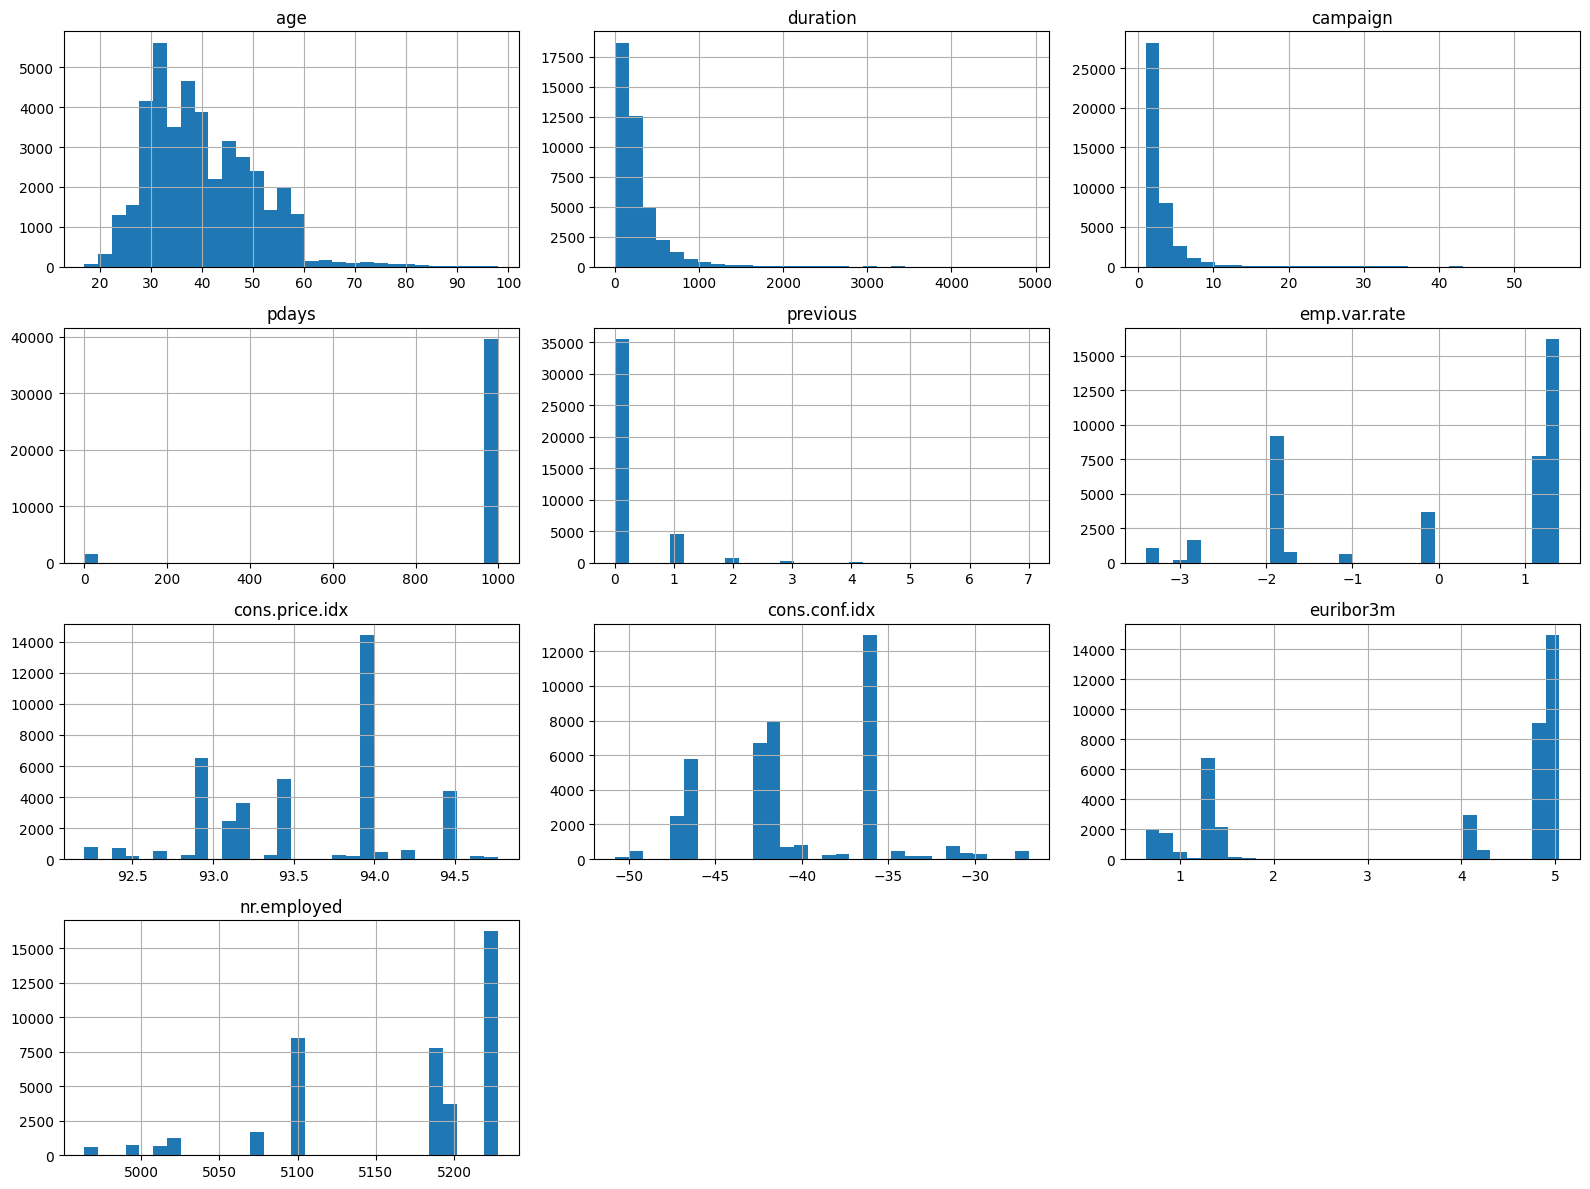

In [ ]:
#Distribuição das variáveis numéricas:

df.hist(figsize=(16, 12), bins=30)
plt.tight_layout()
plt.show()

In [ ]:
pd.DataFrame({
    "count": df["pdays"].value_counts().sort_index(),
    "porcentagem (%)": df["pdays"].value_counts(normalize=True).sort_index() * 100
}).round(2)

,count,porcentagem (%)
pdays,,
0,15,0.04
1,26,0.06
2,61,0.15
3,439,1.07
4,118,0.29
5,46,0.11
6,412,1.00
7,60,0.15
8,18,0.04


In [ ]:
#Distribuição das variáveis categóricas:
variaveis_categoricas = [
    "job", "marital", "education", "default",
    "housing", "loan", "contact", "month",
    "day_of_week", "poutcome"
]

for coluna in variaveis_categoricas:
    print(f"\n{coluna}")
    print(df[coluna].value_counts(dropna=False))


job
job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
NaN                330
Name: count, dtype: int64

marital
marital
married     24928
single      11568
divorced     4612
NaN            80
Name: count, dtype: int64

education
education
university.degree      12168
high.school             9515
basic.9y                6045
professional.course     5243
basic.4y                4176
basic.6y                2292
NaN                     1731
illiterate                18
Name: count, dtype: int64

default
default
no     32588
NaN     8597
yes        3
Name: count, dtype: int64

housing
housing
yes    21576
no     18622
NaN      990
Name: count, dtype: int64

loan
loan
no     33950
yes     6248
NaN      990
Name: count, dtype: int64

contact
contact
cellular     26144
telephone    15044


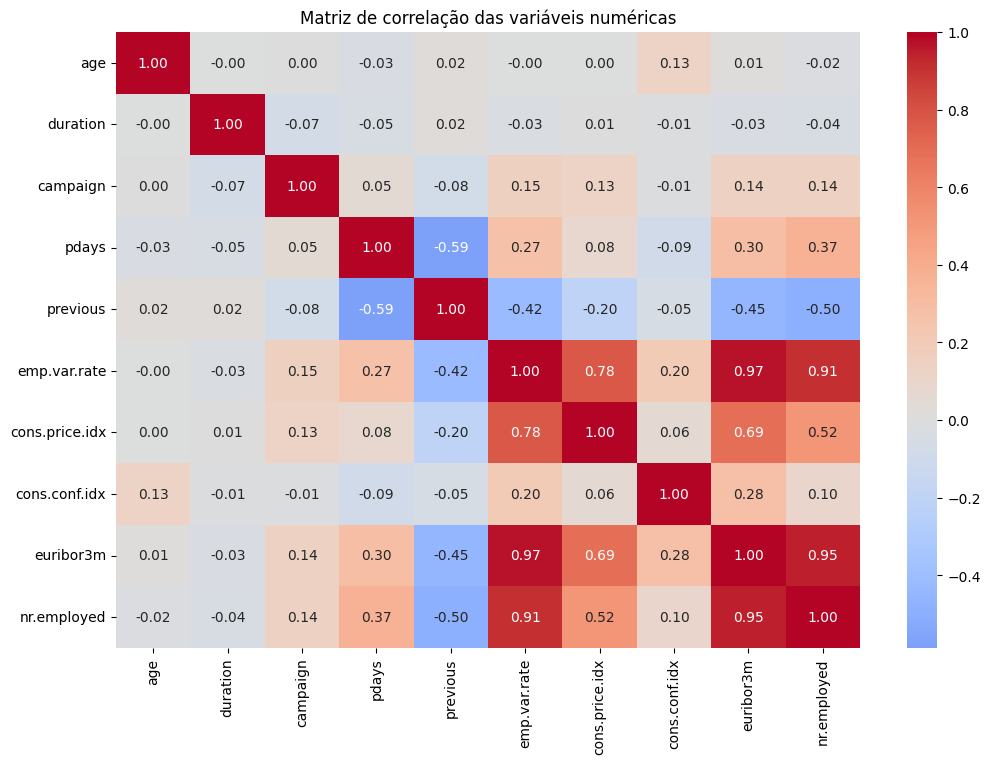

In [ ]:
#Correlação das variáveis:
df_numerico = df.select_dtypes(include="number")

correlacao = df_numerico.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlacao,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Matriz de correlação das variáveis numéricas")
plt.show()

In [ ]:
#Outliers:
variaveis_numericas = df.select_dtypes(include="number").columns

for coluna in variaveis_numericas:
    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    outliers = (
        (df[coluna] < limite_inferior) |
        (df[coluna] > limite_superior)
    )

    print(
        coluna,
        "Outliers:", outliers.sum(),
        f"({outliers.mean() * 100:.2f}%)"
    )

age Outliers: 469 (1.14%)
duration Outliers: 2963 (7.19%)
campaign Outliers: 2406 (5.84%)
pdays Outliers: 1515 (3.68%)
previous Outliers: 5625 (13.66%)
emp.var.rate Outliers: 0 (0.00%)
cons.price.idx Outliers: 0 (0.00%)
cons.conf.idx Outliers: 447 (1.09%)
euribor3m Outliers: 0 (0.00%)
nr.employed Outliers: 0 (0.00%)


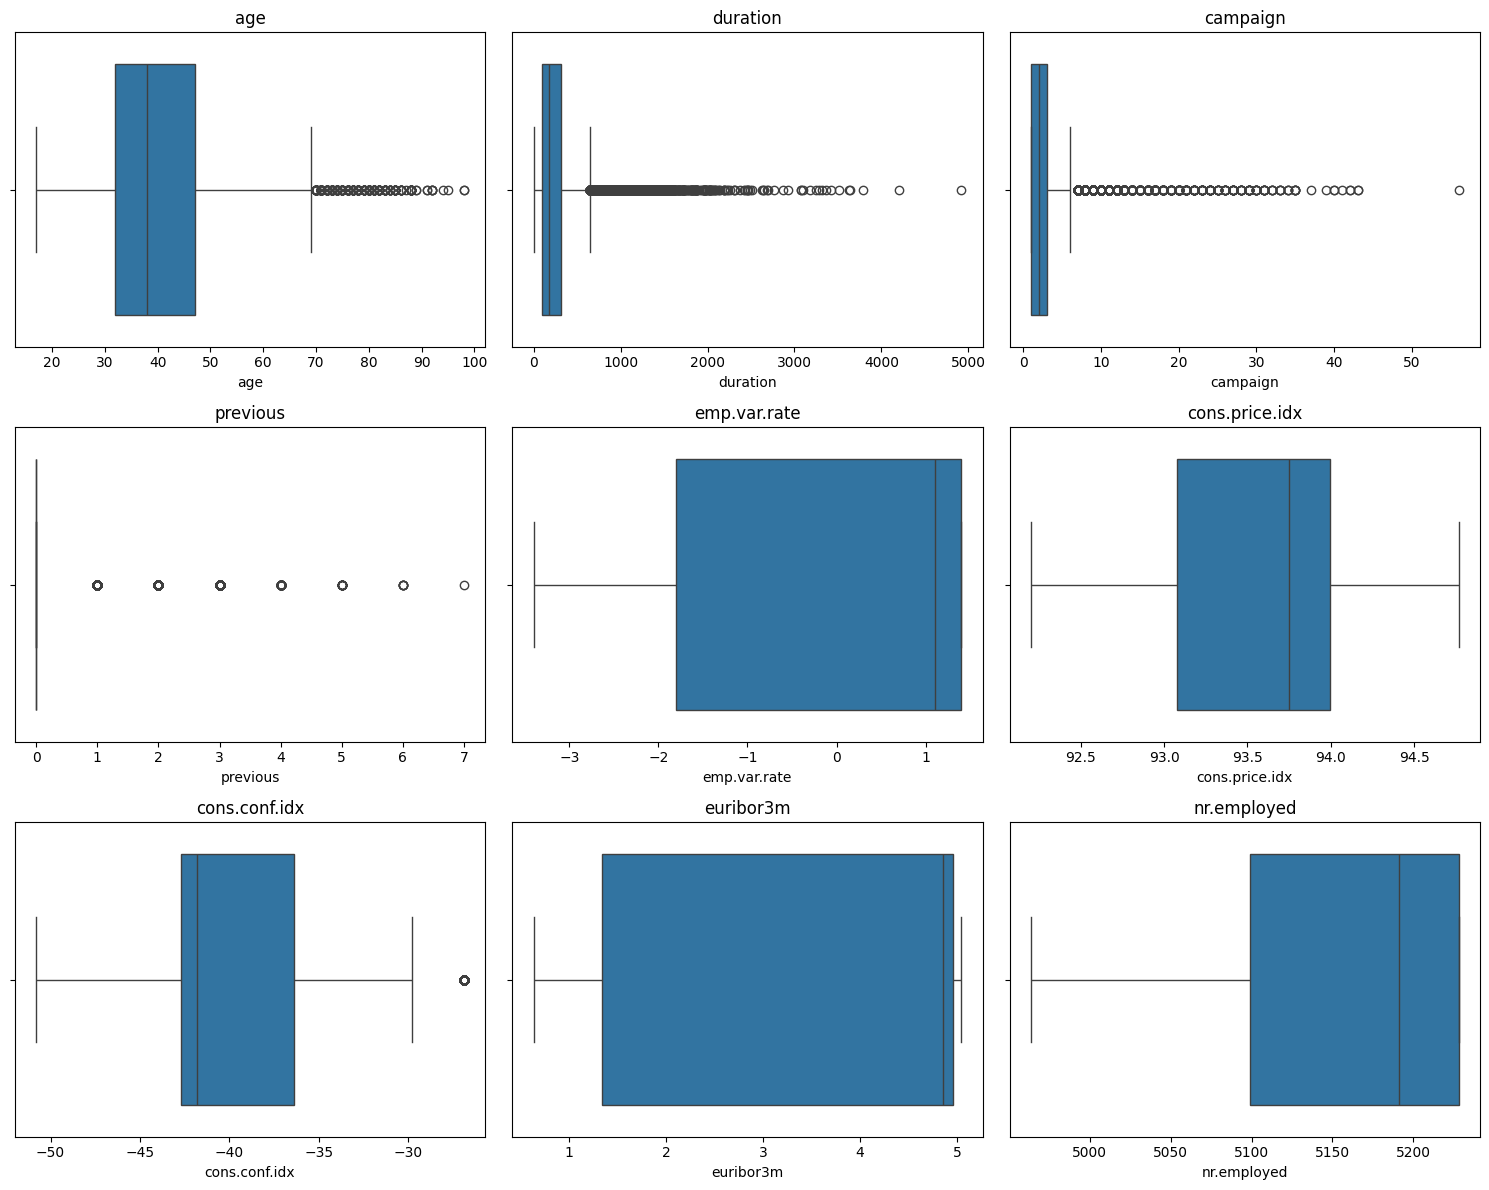

In [ ]:
variaveis = [
    "age", "duration", "campaign",
    "previous", "emp.var.rate",
    "cons.price.idx", "cons.conf.idx",
    "euribor3m", "nr.employed"
]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for coluna, ax in zip(variaveis, axes.flatten()):
    sns.boxplot(x=df[coluna], ax=ax)
    ax.set_title(coluna)

plt.tight_layout()
plt.show()

**Relatório Data Understanding**

**1. Inventário dos Dados**

A base reúne informações sobre clientes, características das campanhas de marketing direto, histórico de contatos anteriores e indicadores econômicos referentes ao período das campanhas. Entre as informações disponíveis estão idade (`age`), profissão (`job`), escolaridade (`education`), estado civil (`marital`), características de crédito (`default`, `housing` e `loan`), meio e período de contato (`contact`, `month` e `day_of_week`), frequência de abordagens (`campaign` e `previous`), histórico de campanhas anteriores (`pdays` e `poutcome`) e indicadores econômicos (`emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m` e `nr.employed`).



Não estão disponíveis informações como custos das ligações, remuneração dos atendentes, valor dos contratos e motivos de recusa. Dessa forma, o projeto consegue investigar a probabilidade de adesão e a priorização de contatos, mas não calcular diretamente o lucro, o custo por contrato ou a rentabilidade real da campanha.

**2. Descrição dos Dados**

A base possui 41.188 registros e 21 variáveis, sendo 20 delas explicativas e uma a variável-alvo (`y`). A variável-alvo é uma variável binária que indica se houve adesão ao depósito. Existem 36.548 (88,73%) registros de pessoas que foram contatadas e não aderiram ao depósito e 4.640 (11,27%) registos de pessoas que aderiram.


Entre as variáveis numéricas estão: idade (`age`), duração da ligação em segundos (`duration`), número de contatos realizados durante a campanha atual (`campaign`), número de dias desde o último contato de uma campanha anterior (`pdays`), número de contatos realizados antes da campanha atual (`previous`) e indicadores econômicos, como taxa de variação do emprego (`emp.var.rate`), índice de preços ao consumidor (`cons.price.idx`), índice de confiança do consumidor (`cons.conf.idx`), taxa Euribor de 3 meses (`euribor3m`) e número de empregados (`nr.employed`).


As variáveis categóricas são: profissão (`job`), estado civil (`marital`), escolaridade (`education`), situação de inadimplência (`default`), existência de empréstimo imobiliário (`housing`), existência de empréstimo pessoal (`loan`), tipo de contato (`contact`), mês (`month`), dia da semana (`day_of_week`) e resultado da campanha anterior (`poutcome`).

**3. Exploração dos Dados**




*   **Hipótese 1:** Clientes que tiveram uma campanha de marketing anterior
bem-sucedida apresentam maior taxa de adesão na campanha atual.

  Comparar a taxa de adesão (y = yes) entre clientes com resultado anterior "success", "failure" e "nonexistent".


*   **Hipótese 2:** Clientes que receberam menos contatos durante a campanha atual apresentam maior taxa de adesão.

  Comparar a taxa de adesão conforme o número de contatos recebidos, por exemplo, entre clientes com 1, 2, 3 ou mais contatos.


*  **Hipótese 3:** A taxa de adesão varia conforme as condições macroeconômicas vigentes no período da campanha.

  Comparar a taxa de adesão entre diferentes valores ou períodos dos indicadores econômicos.

**4. Qualidade dos Dados**



*   **Valores ausentes em variáveis categóricas:** `job` (0,80%), `marital` (0,19%), `housing` (2,40%), `loan` (2,40%), `education` (4,20%). Como os valores ausentes representantam uma pequena parcela de cada variável, será considerada a possibilidade de tratá-los substituindo esses NAs pela mediana de cada variável.
*   **A variável `default`:** 20,87% dos seus registros são valores ausentes. Além disso, 32.588 (79,12%) dos registros estão classificados como "no" e apenas 3 como "yes". Por conta desses problemas, é provável que a variável contribua pouco para o desempenho do modelo. Assim, será considerada a possibiidade de descartá-la.
*   **A variável `pdays`:** Apresenta uma concentração elevada no valor 999, presente em 96,32% dos registros. Esse valor é um código que indica que o cliente não foi contatado em uma campanha anterior, e não representa uma quantidade real de dias. Para evitar interpretações equivocadas, a variável será transformada em uma variável binária que identifica se houve contato anterior (1) ou não (0). Essa transformação também facilita a análise da relação entre o histórico de contatos e a adesão à campanha.
*   **Desbalanceamento da variável-alvo:** A variável possui 88,73% dos seus registros como "no" e apenas 11,27% como yes. Serão avaliadas a possibilidade de técnicas de balanceamento0, como SMOTE.
*   **Valores extremos e alta correlação de variáveis:** Foram encontrados valores extremos nas variáveis numéricas `previous` (13,66% dos registros), `duration` (7,19%), `campaign` (5,84%), `age` (1,14%) e `cons.conf.idx` (1,09%). Também foi identificada alta correlação entre os indicadores macroeconômicos `euribor3m` e `emp.var.rate` (0,97), `nr.employed` e `euribor3m` (0,95), e `nr.employed` e `emp.var.rate` (0,91), indicando possível redundância de informação. Esses casos serão investigados a fim de avaliar a necessidade da exclusão de alguns valores.


**5. Riscos:**


*   **Data leakage:** A variável `duration` será excluída das variáveis preditoras, pois só é conhecida após a ligação, evitando vazamento de informação.
*   **Desbalanceamento da variável-alvo:** A predominância de registros "no" pode dificultar a identificação dos clientes que aderem à oferta.
*   **Representatividade:** A base apresenta limitações de representatividade, pois corresponde a campanhas de uma instituição bancária portuguesa em um contexto histórico específico, não sendo possível generalizar automaticamente os resultados para outros bancos, países ou períodos.
*   **Contatos repetidos:** A base pode conter registros de contatos de um mesmo cliente, mas não possui identificador individual que permita controlar essa ocorrência na divisão entre treino e teste.
*   **Viés:** O modelo pode reproduzir padrões das campanhas anteriores, favorecendo perfis que historicamente foram mais contatados ou aderiram mais à oferta. Isso pode limitar as oportunidades oferecidas a outros grupos.